<a href="https://colab.research.google.com/github/24f3003058/DL-GenAI/blob/main/Week1/LinearRegression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Linear regression using pytorch



In [3]:
import torch
from torch import nn
import matplotlib.pyplot as plt

In [4]:
torch.__version__

'2.11.0+cu130'

In [5]:

print(torch.cuda.is_available())

True


In [6]:
#cuda version
print(torch.version.cuda)

13.0


In [7]:
#GPU Device
torch.cuda.get_device_name(0)

'Tesla T4'

In [8]:
#defining data
weight=0.8
bias=0.1

start=0
end=1
step=0.01
X=torch.arange(start,end,step).unsqueeze(dim=1)
y= weight*X + bias

print(f"X(first 10):{y[:10].flatten()}")
print(f"y(first 10 ):{y[:10].flatten()}")
print(X.shape,y.shape)

X(first 10):tensor([0.1000, 0.1080, 0.1160, 0.1240, 0.1320, 0.1400, 0.1480, 0.1560, 0.1640,
        0.1720])
y(first 10 ):tensor([0.1000, 0.1080, 0.1160, 0.1240, 0.1320, 0.1400, 0.1480, 0.1560, 0.1640,
        0.1720])
torch.Size([100, 1]) torch.Size([100, 1])


In [9]:
train_split=int(0.8 *len(X))
X_train,y_train=X[:train_split],y[:train_split]
X_test,y_test=X[train_split:],y[train_split:]

print(len(X_train),len(y_train))
print(len(X_test),len(y_test))

assert len(X_train) +len(X_test) == len(X)

80 80
20 20


In [10]:
from torch.utils.data import TensorDataset, DataLoader
train_dataset=TensorDataset(X_train,y_train)
test_dataset=TensorDataset(X_test,y_test)

BATCH_SIZE=8
NUM_WORKERS=0

train_dataloader =DataLoader(dataset=train_dataset,batch_size=BATCH_SIZE,shuffle=True,num_workers=NUM_WORKERS)
test_dataloader=DataLoader(dataset=train_dataset,batch_size=BATCH_SIZE,shuffle=False,num_workers=NUM_WORKERS)

print(len(train_dataloader),len(test_dataloader),BATCH_SIZE,len(train_dataset),len(test_dataset))


10 10 8 80 20


In [11]:
for batch_x, batch_y in train_dataloader:
  print(batch_x.shape,batch_y.shape)
  print("Batch x",batch_x)
  print("Batch y",batch_y)

torch.Size([8, 1]) torch.Size([8, 1])
Batch x tensor([[0.3700],
        [0.0500],
        [0.4400],
        [0.3800],
        [0.5900],
        [0.7500],
        [0.5700],
        [0.6800]])
Batch y tensor([[0.3960],
        [0.1400],
        [0.4520],
        [0.4040],
        [0.5720],
        [0.7000],
        [0.5560],
        [0.6440]])
torch.Size([8, 1]) torch.Size([8, 1])
Batch x tensor([[0.2500],
        [0.3300],
        [0.2300],
        [0.6900],
        [0.4700],
        [0.0000],
        [0.7600],
        [0.6400]])
Batch y tensor([[0.3000],
        [0.3640],
        [0.2840],
        [0.6520],
        [0.4760],
        [0.1000],
        [0.7080],
        [0.6120]])
torch.Size([8, 1]) torch.Size([8, 1])
Batch x tensor([[0.5300],
        [0.1200],
        [0.6700],
        [0.3900],
        [0.3200],
        [0.2600],
        [0.4500],
        [0.7000]])
Batch y tensor([[0.5240],
        [0.1960],
        [0.6360],
        [0.4120],
        [0.3560],
        [0.3080],
     

In [15]:
def plot_predictions(train_data=X_train,
                     train_labels=y_train,
                     test_data=X_test,
                     test_labels=y_test,
                     predictions=None):
  plt.figure(figsize=(10,7))
  plt.scatter(train_data,train_labels,c='green',s=25,alpha=0.5,label='Training data',marker='o')
  plt.scatter(test_data,test_labels,c='blue',s=15,alpha=0.7,label='Testing data',marker='s')

  if predictions is not None:
    plt.scatter(test_data,predictions ,c='red',s=25,alpha=0.8,marker='^')
  plt.xlabel("Input features(x)",fontsize=12)
  plt.ylabel("Target values(y)",fontsize=12)
  plt.title("Linear regression")
  plt.legend(fontsize=11)
  plt.grid(True,alpha=0.3)
  plt.tight_layout()


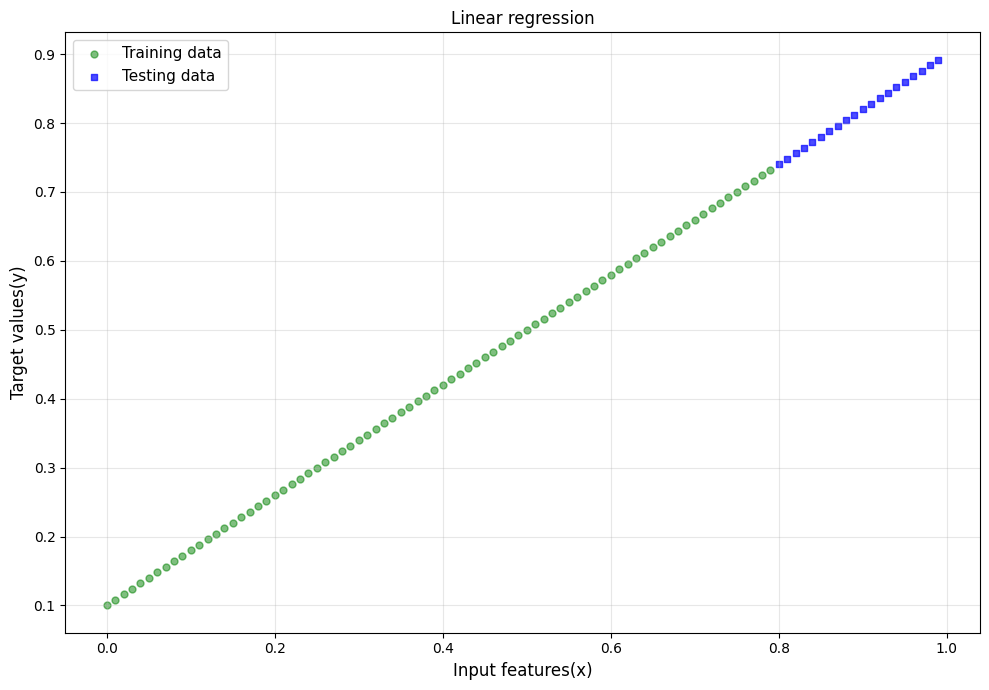

In [16]:
plot_predictions()

In [18]:
import torch.nn as nn
class LinearRegressionModel(nn.Module):
  def __init__(self):
    super().__init__()
    self.weights=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)
    self.bias=nn.Parameter(torch.randn(1,dtype=torch.float),requires_grad=True)

  def forward(self,x:torch.Tensor)->torch.Tensor:
    return self.weights * x +self.bias

model=LinearRegressionModel()
x=torch.tensor([[2.0],[3.0],[4.0]])
x, x.shape
y_pred=model(x)
print(y_pred)

tensor([[-0.2328],
        [-0.6127],
        [-0.9926]], grad_fn=<AddBackward0>)
